# Dealer-like liquidity provision around extreme order-flow shocks

**Question.** When order flow becomes extremely one-sided, who supplies liquidity, how fast does the book
recover, and do prices revert, as dealer inventory models predict, or stay put, as adverse selection predicts?

This notebook is the narrative companion to `REPORT.md`. All estimates come from `scripts/run_all.py`
(tables in `results/tables/`, figures in `results/figures/`).

| Role | Meaning |
|---|---|
| **primary** | the tests the conclusions rest on (declared specification below) |
| **secondary** | supporting measures, longer horizons, robustness grid |
| **exploratory** | dealer-theory proxies D1–D6 and shock-type splits |

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import display, Image
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 70)
from mm.config import FIGS, TABLES, RAW_FI
from mm.fi2010 import read_raw_book, surviving_pairs

def T(name, cols=None, rnd=3):
    d = pd.read_csv(TABLES / f"{name}.csv")
    return (d[cols] if cols else d).round(rnd)

def F(name):
    display(Image(filename=str(FIGS / name)))

## 1. Data and validation checks

| | FI-2010 | LOBSTER (free sample) |
|---|---|---|
| Market | Nasdaq Helsinki, 5 stocks × 10 days (June 2010) | NASDAQ: AAPL, AMZN, GOOG, INTC, MSFT, 21 June 2012 |
| Content | 10-level book, one snapshot per 10 events | 10-level book plus every message (orders, cancels, executions, order IDs) |

**Check 1: FI-2010 must be split into stock-days.** The files stack stocks and days. A day boundary is a
snapshot where *no* (side, price, size) pair survives from the previous one.

In [2]:
B = read_raw_book(RAW_FI / "Train_Dst_NoAuction_DecPre_CF_7.txt")
surv = surviving_pairs(B)
print("histogram of surviving pairs (0..20):", np.bincount(surv, minlength=21))
print("boundaries found:", int((surv <= 2).sum()), " expected 5 stocks x 7 days - 1 = 34")
del B

histogram of surviving pairs (0..20): [   32     1     1     0     0     3    11    23    83   403  1493  4734
 11186 22085 34458 42969 43577 36554 28185 12478 16473]
boundaries found: 34  expected 5 stocks x 7 days - 1 = 34


Exactly 34 breaks, and no within-day step has fewer than 5 surviving pairs, so the split is exact (50 stock-days in total).

**Check 2: LOBSTER trade signs.**
* Visible executions are signed by the executed order's side; they match the price side of the mid 100% of the time.
* Hidden executions' direction field is unreliable: in INTC and MSFT ~70% print at the mid and the field agrees
  with the price side only ~15% of the time. They are therefore signed by the quote rule, and those exactly at
  the mid are dropped (see `VALIDATION_LOG.md`).

In [3]:
display(T("01_descriptives"))

,dataset,stock,snapshots,segments,mid,spread_ticks,rel_spread_bps,dbid1,dask1,dbid10,dask10,imb1,imb10,ofi1n,rvol20,buy_vol,sell_vol
0,FI-2010,KESBV,29744,10,26.830,5.984,22.323,397.904,407.973,4961.612,5058.851,0.008,-0.005,-0.001,2.621,NaN,NaN
1,FI-2010,OUT1V,67935,10,12.839,2.064,16.101,1731.389,1724.969,32249.250,30832.448,-0.004,0.019,0.002,2.367,NaN,NaN
2,FI-2010,RTRKS,86605,10,12.742,2.298,18.054,1824.511,1639.845,29273.504,30217.177,0.032,-0.007,0.003,1.853,NaN,NaN
3,FI-2010,SAMPO,62898,10,17.447,2.105,12.076,1877.172,2073.174,32710.594,34356.988,-0.012,-0.026,0.002,1.819,NaN,NaN
4,FI-2010,WRT1V,147155,10,35.494,5.653,15.969,395.512,487.544,5367.073,5886.673,-0.056,-0.043,0.001,1.130,NaN,NaN
5,LOBSTER,AAPL,35142,1,583.441,15.452,2.647,181.430,136.734,1774.719,1435.084,0.072,0.079,-0.040,0.382,30.251,33.629
6,LOBSTER,AMZN,24343,1,222.827,13.069,5.864,247.230,131.099,1858.909,1433.337,0.102,0.093,0.003,0.630,12.736,13.823
7,LOBSTER,GOOG,13118,1,570.881,28.684,5.021,159.814,123.443,1239.332,904.798,0.003,0.129,-0.057,0.649,20.355,20.227
8,LOBSTER,INTC,52230,1,27.047,1.210,4.474,15456.187,13455.752,151740.537,135647.768,0.043,0.055,-0.003,0.256,62.714,79.107
9,LOBSTER,MSFT,57484,1,30.556,1.220,3.994,13605.799,14076.067,146103.615,148740.078,-0.028,-0.012,-0.004,0.286,66.987,68.423


## 2. Primary design

* **Shock:** order-flow imbalance (Cont, Kukanov & Stoikov 2014) summed over 5 steps is in the stock's 1% tail.
  Events are ≥ 100 steps apart and windows stay inside a stock-day. One step = 10 book events, which is
  32–161 s per 100 steps in LOBSTER, depending on the stock.
* **Controls:** 5 calm moments from the same stock-day, matched on spread, depth, imbalance, volatility and time
  of day. Two kinds:
  * matched on the state *before* the shock, to measure its effect;
  * matched on the *depleted* book after it, so that mechanical refilling is not counted as provision.
* **Windows:** shock [−5, 0], provision (0, 10], recovery (10, 100]; long horizon 300 steps.
* **Inference:** SEs clustered by stock-day (FI-2010, 50 clusters) or stock × 30 min (LOBSTER, 60 clusters).
  CIs use t with G − 1 df. `p_holm` = Holm adjustment across all rows of a table.

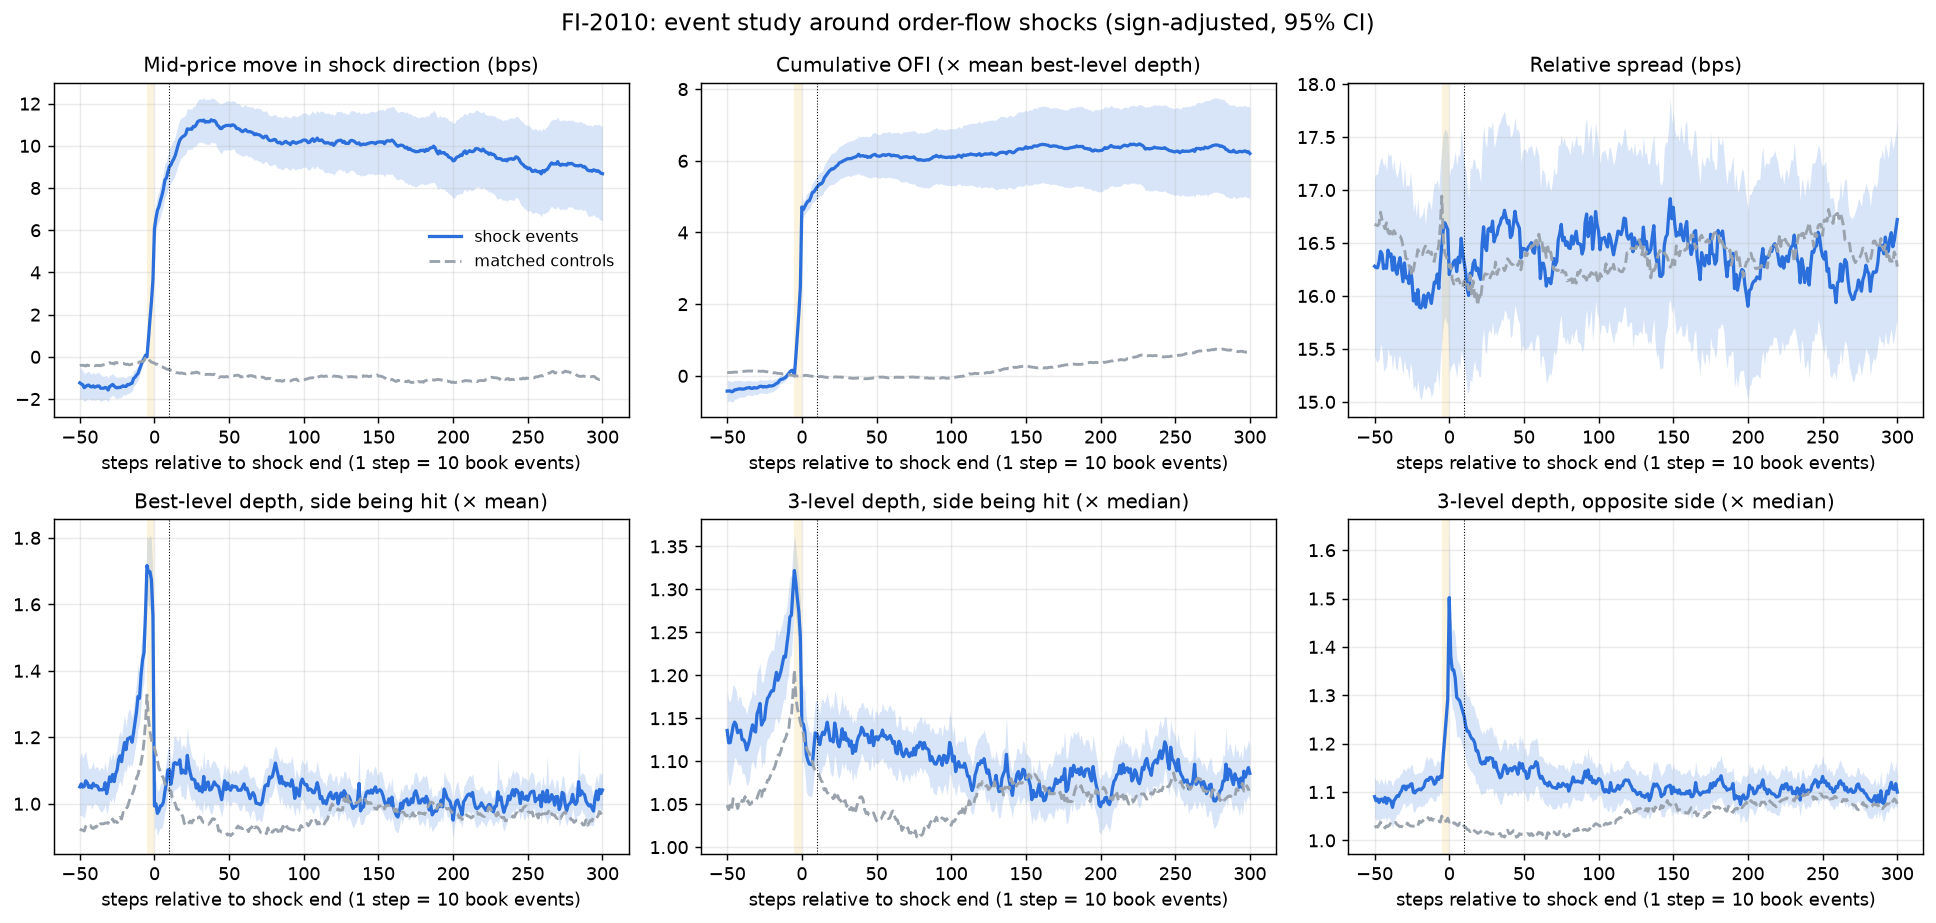

In [4]:
F("fig1_event_study_FI-2010.png")

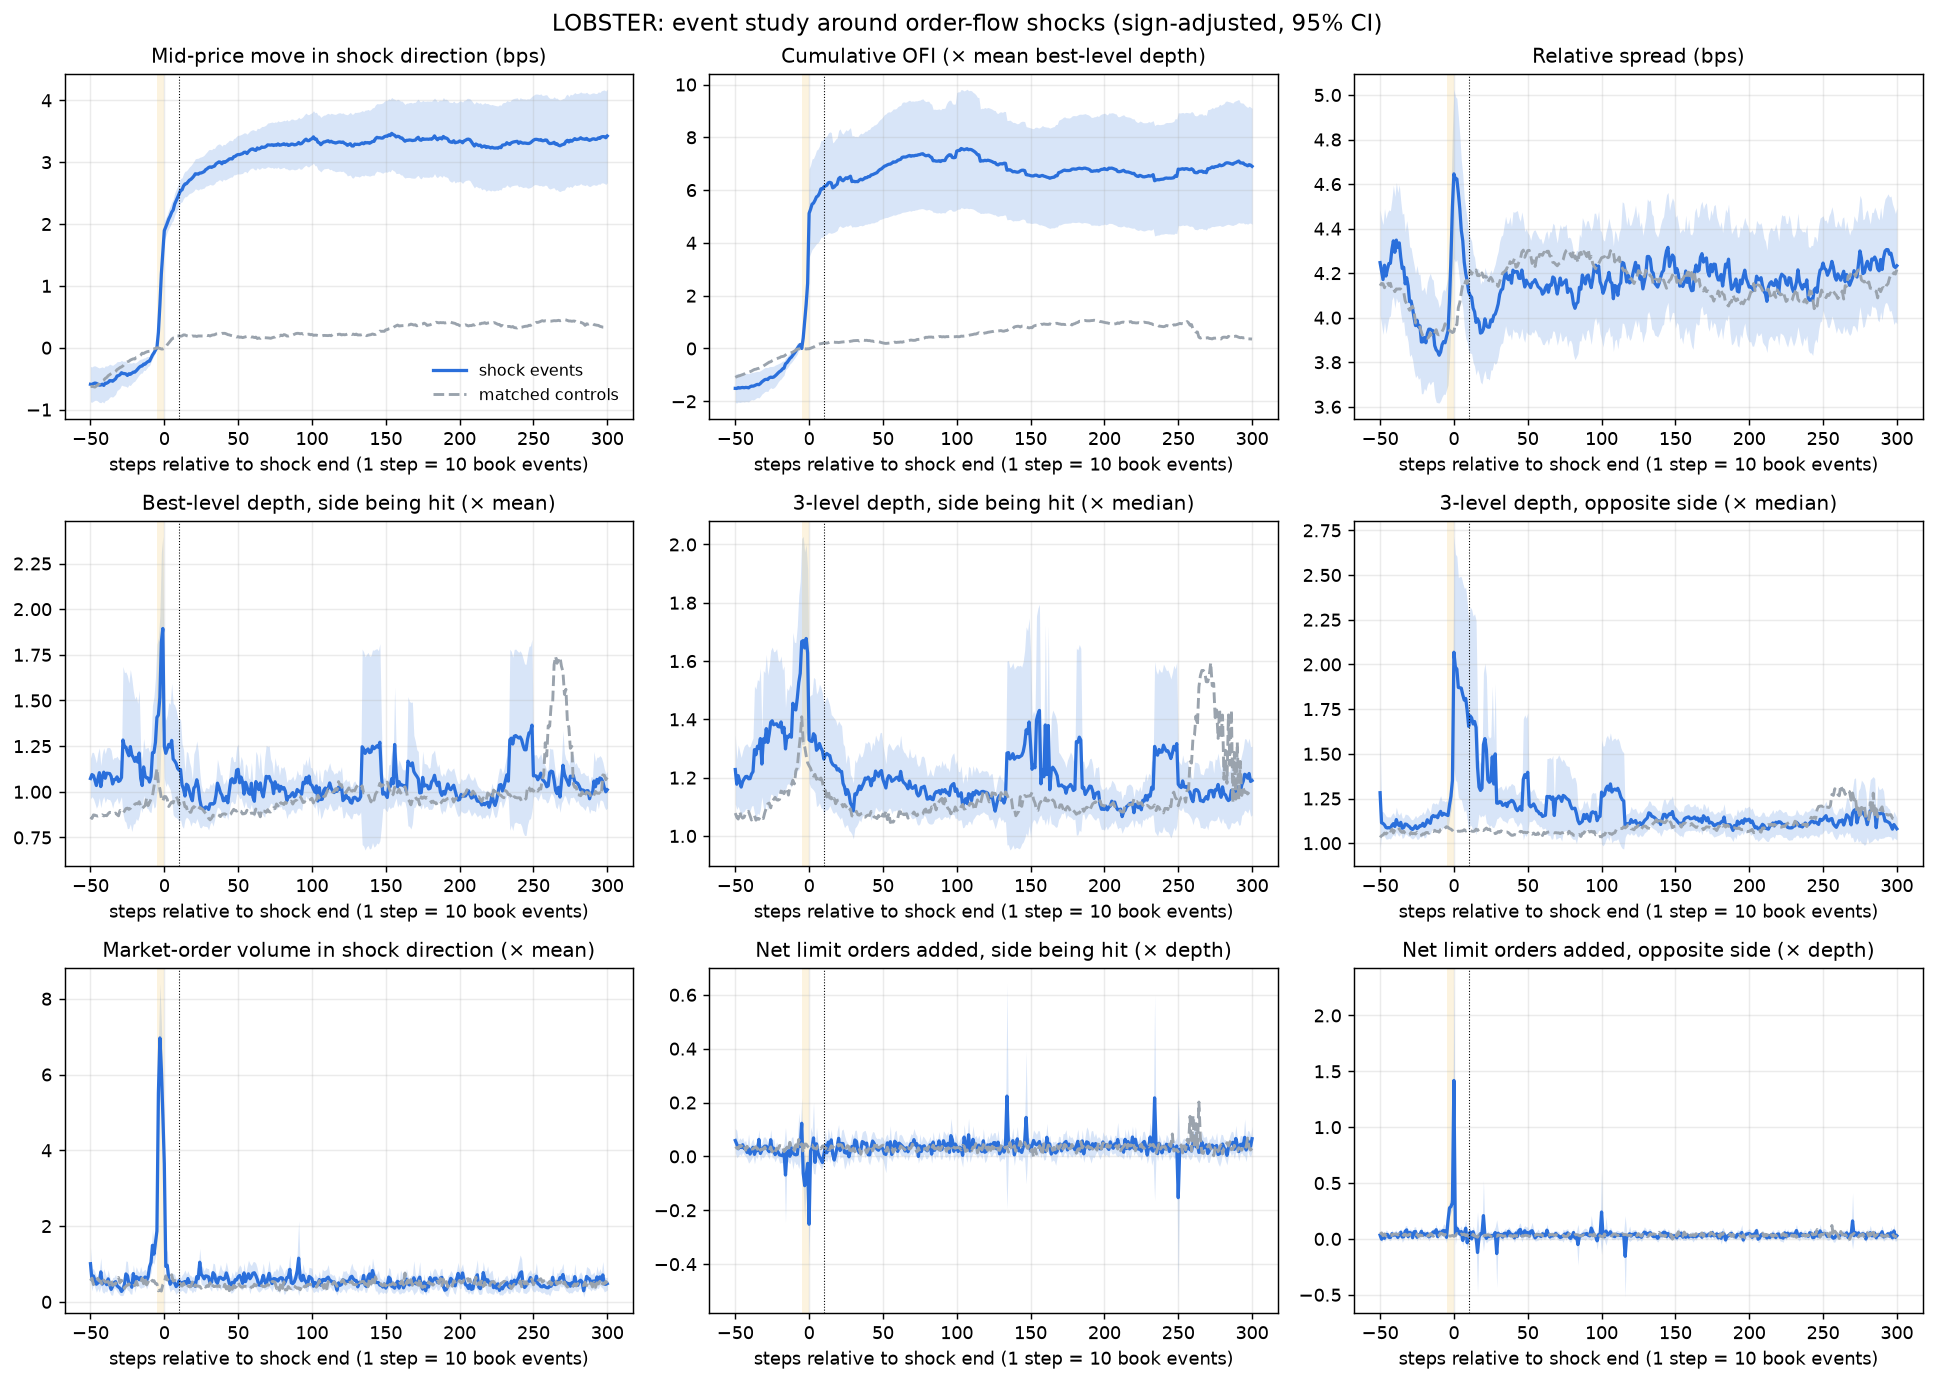

In [5]:
F("fig1_event_study_LOBSTER.png")

## 3. Hypotheses H1–H4 (primary)

In [6]:
cols = ["role", "hypothesis", "measure", "mean", "ci_low", "ci_high", "p", "p_holm", "n", "clusters"]
display(T("02_hypotheses_FI-2010", cols)); display(T("02_hypotheses_LOBSTER", cols))

,role,hypothesis,measure,mean,ci_low,ci_high,p,p_holm,n,clusters
0,primary,H1,"Δ relative spread (bps), shock vs control",0.393,-0.132,0.918,0.139,0.556,1269,50
1,secondary,H1,"Δ depth on hit side, 3 lvls (× median)",-0.110,-0.164,-0.057,0.000,0.001,1269,50
2,primary,H1,"Δ depth on hit side, best level (× mean)",-0.564,-0.656,-0.472,0.000,0.000,1269,50
3,secondary,H1,"Δ depth on hit side, 10 lvls (× median)",0.002,-0.017,0.022,0.800,0.800,1269,50
4,primary,H1,Δ book imbalance toward pressure,0.151,0.115,0.187,0.000,0.000,1269,50
5,primary,H2,"Contrarian order flow (0,K1] vs same-state control",-0.555,-0.868,-0.242,0.001,0.006,1269,50
6,primary,H2,"Hit-side refill (0,K1] vs same-state control",0.022,-0.014,0.057,0.223,0.556,1269,50
7,primary,H2,"Hit-side quote improvements (0,K1] vs control (count)",-0.071,-0.141,-0.002,0.045,0.223,1269,50
8,primary,H3/H4,"Price drift after shock (0,K2] vs control, bps",4.993,3.349,6.636,0.000,0.000,1269,50
9,secondary,H3/H4,"Price drift after shock (0,300] vs control, bps",3.361,0.935,5.786,0.008,0.046,1269,50


,role,hypothesis,measure,mean,ci_low,ci_high,p,p_holm,n,clusters
0,primary,H1,"Δ relative spread (bps), shock vs control",0.754,0.436,1.071,0.000,0.000,657,60
1,secondary,H1,"Δ depth on hit side, 3 lvls (× median)",-0.169,-0.334,-0.005,0.043,0.217,657,60
2,primary,H1,"Δ depth on hit side, best level (× mean)",-0.005,-0.238,0.229,0.967,1.000,657,60
3,secondary,H1,"Δ depth on hit side, 10 lvls (× median)",-0.081,-0.135,-0.028,0.004,0.025,657,60
4,primary,H1,Δ book imbalance toward pressure,0.124,0.073,0.174,0.000,0.000,657,60
5,primary,H2,"Contrarian order flow (0,K1] vs same-state control",-1.000,-1.451,-0.548,0.000,0.000,657,60
6,primary,H2,"Hit-side refill (0,K1] vs same-state control",0.047,-0.074,0.167,0.439,1.000,657,60
7,primary,H2,"Hit-side quote improvements (0,K1] vs control (count)",-0.209,-0.343,-0.074,0.003,0.023,657,60
8,secondary,H2,"Net limit orders added on hit side (0,K1] vs control",-0.147,-0.315,0.021,0.085,0.340,657,60
9,primary,H3/H4,"Price drift after shock (0,K2] vs control, bps",1.261,0.818,1.704,0.000,0.000,657,60


**Sensitivity of inference to the clustering unit.** Only five stocks underlie each dataset, so stock-level
clustering (4 df) is the harshest check. Effects that survive it are the most defensible.

In [7]:
display(T("05_cluster_sensitivity"))
display(T("04_by_stock_FI-2010")); display(T("04_by_stock_LOBSTER"))

,dataset,measure,clustering,clusters,mean,se,ci_low,ci_high,t,p
0,FI-2010,price impact (bps),stock-day (50),50,6.080,0.327,5.423,6.737,18.598,0.000
1,FI-2010,price impact (bps),day (10),10,6.080,0.192,5.646,6.514,31.684,0.000
2,FI-2010,price impact (bps),stock (5),5,6.080,0.908,3.560,8.600,6.699,0.003
3,FI-2010,H1 best-level depth,stock-day (50),50,-0.564,0.046,-0.656,-0.472,-12.316,0.000
4,FI-2010,H1 best-level depth,day (10),10,-0.564,0.050,-0.678,-0.450,-11.185,0.000
5,FI-2010,H1 best-level depth,stock (5),5,-0.564,0.041,-0.679,-0.449,-13.622,0.000
6,FI-2010,H1 spread (bps),stock-day (50),50,0.393,0.261,-0.132,0.918,1.504,0.139
7,FI-2010,H1 spread (bps),day (10),10,0.393,0.205,-0.072,0.858,1.913,0.088
8,FI-2010,H1 spread (bps),stock (5),5,0.393,0.365,-0.619,1.405,1.078,0.342
9,FI-2010,H2 contrarian flow,stock-day (50),50,-0.555,0.156,-0.868,-0.242,-3.562,0.001


,dataset,stock,events,impact_bps,h1_spread_bps,h1_best_depth,h2_contrarian_flow,h2_refill,drift_abn_bps,share_recovered,median_t_recover
0,FI-2010,KESBV,102,10.938,-0.112,-0.510,0.872,0.004,1.717,0.980,17.0
1,FI-2010,OUT1V,231,7.180,1.757,-0.540,-0.549,0.045,3.838,0.944,16.0
2,FI-2010,RTRKS,280,6.591,0.063,-0.447,-0.315,0.017,4.638,0.914,17.0
3,FI-2010,SAMPO,215,5.901,0.701,-0.701,-0.846,-0.073,2.986,0.953,12.0
4,FI-2010,WRT1V,441,4.144,-0.145,-0.597,-0.899,0.062,7.558,0.905,20.0


,dataset,stock,events,impact_bps,h1_spread_bps,h1_best_depth,h2_contrarian_flow,h2_refill,drift_abn_bps,share_recovered,median_t_recover
0,LOBSTER,AAPL,105,1.063,-0.452,-0.627,-2.892,0.738,0.429,0.962,7.0
1,LOBSTER,AMZN,63,2.266,-0.276,-0.622,-1.886,-0.259,2.061,0.921,12.0
2,LOBSTER,GOOG,45,1.488,0.366,-1.027,-1.505,-0.403,1.307,0.956,15.0
3,LOBSTER,INTC,205,2.132,1.806,0.299,-0.306,-0.035,1.021,0.859,27.0
4,LOBSTER,MSFT,239,2.035,0.725,0.363,-0.434,-0.022,1.614,0.874,20.0


## 4. H3: provision and recovery (secondary)

Per event: $Recovery_i=\beta_0+\beta_1 LP_i+\gamma' controls_i+FE+\varepsilon_i$, with LP measured in
(0, 10] and recovery in (10, 100]. LP is standardised, so β is per 1 SD. `t_recover` overlaps the provision
window and is descriptive only.

In [8]:
display(T("03_h3_regressions_FI-2010")); display(T("03_h3_regressions_LOBSTER"))

,dataset,LP,outcome,beta_per_sd,se,t,p,n,r2,sig,p_holm
0,FI-2010,lp_flow,reversal_bps,0.534,1.259,0.425,0.671,1269,0.060,NaN,1.000
1,FI-2010,lp_flow,spread_gap_K2,0.213,0.282,0.754,0.451,1269,0.352,NaN,1.000
2,FI-2010,lp_flow,depth_gap_K2,0.019,0.027,0.700,0.484,1269,0.172,NaN,1.000
3,FI-2010,lp_flow,t_recover,-4.150,3.308,-1.254,0.210,1269,0.187,NaN,1.000
4,FI-2010,lp_refill,reversal_bps,1.064,0.604,1.762,0.078,1269,0.062,*,0.625
5,FI-2010,lp_refill,spread_gap_K2,-0.067,0.241,-0.278,0.781,1269,0.352,NaN,1.000
6,FI-2010,lp_refill,depth_gap_K2,0.008,0.016,0.488,0.626,1269,0.172,NaN,1.000
7,FI-2010,lp_refill,t_recover,-1.855,2.572,-0.721,0.471,1269,0.186,NaN,1.000


,dataset,LP,outcome,beta_per_sd,se,t,p,n,r2,sig,p_holm
0,LOBSTER,lp_flow,reversal_bps,-0.024,0.201,-0.121,0.903,657,0.066,NaN,1.000
1,LOBSTER,lp_flow,spread_gap_K2,0.091,0.048,1.882,0.060,657,0.151,*,0.538
2,LOBSTER,lp_flow,depth_gap_K2,-0.023,0.134,-0.174,0.862,657,0.603,NaN,1.000
3,LOBSTER,lp_flow,t_recover,-1.552,2.653,-0.585,0.558,657,0.139,NaN,1.000
4,LOBSTER,lp_refill,reversal_bps,-0.421,0.181,-2.324,0.020,657,0.071,**,0.221
5,LOBSTER,lp_refill,spread_gap_K2,-0.145,0.064,-2.263,0.024,657,0.154,**,0.236
6,LOBSTER,lp_refill,depth_gap_K2,0.013,0.162,0.080,0.936,657,0.603,NaN,1.000
7,LOBSTER,lp_refill,t_recover,-7.804,4.400,-1.773,0.076,657,0.143,*,0.609
8,LOBSTER,lp_msg,reversal_bps,-0.299,0.314,-0.952,0.341,657,0.068,NaN,1.000
9,LOBSTER,lp_msg,spread_gap_K2,-0.009,0.082,-0.104,0.917,657,0.148,NaN,1.000


## 5. H4: adverse selection, and how much of the price impact reverts

Shock trades are trades in the shock direction during [−5, 10]; normal trades are trades far from any event.
Differences come from OLS with stock fixed effects and log size. The table repeats the estimates on visible-only trades.

In [9]:
display(T("06_h4_adverse_selection_LOBSTER", ["sample", "horizon_s", "measure", "normal_mean_bps",
          "shock_minus_normal_bps", "ci_low", "ci_high", "p_holm", "n_shock", "n_normal"]))

,sample,horizon_s,measure,normal_mean_bps,shock_minus_normal_bps,ci_low,ci_high,p_holm,n_shock,n_normal
0,all signed trades,0,effective half-spread,1.371,0.090,-0.027,0.207,0.133,2688,21896
1,all signed trades,1,impact,1.112,0.944,0.623,1.264,0.000,2688,21896
2,all signed trades,1,realized,0.260,-0.854,-1.103,-0.605,0.000,2688,21896
3,all signed trades,5,impact,1.277,1.229,0.797,1.662,0.000,2688,21896
4,all signed trades,5,realized,0.095,-1.140,-1.505,-0.775,0.000,2688,21896
5,all signed trades,30,impact,1.432,1.122,0.408,1.836,0.010,2688,21896
6,all signed trades,30,realized,-0.061,-1.032,-1.713,-0.352,0.012,2688,21896
7,all signed trades,60,impact,1.545,0.915,0.150,1.680,0.057,2688,21896
8,all signed trades,60,realized,-0.173,-0.825,-1.543,-0.108,0.057,2688,21896
9,visible-only trades,0,effective half-spread,1.515,0.054,-0.081,0.190,0.431,2211,15302


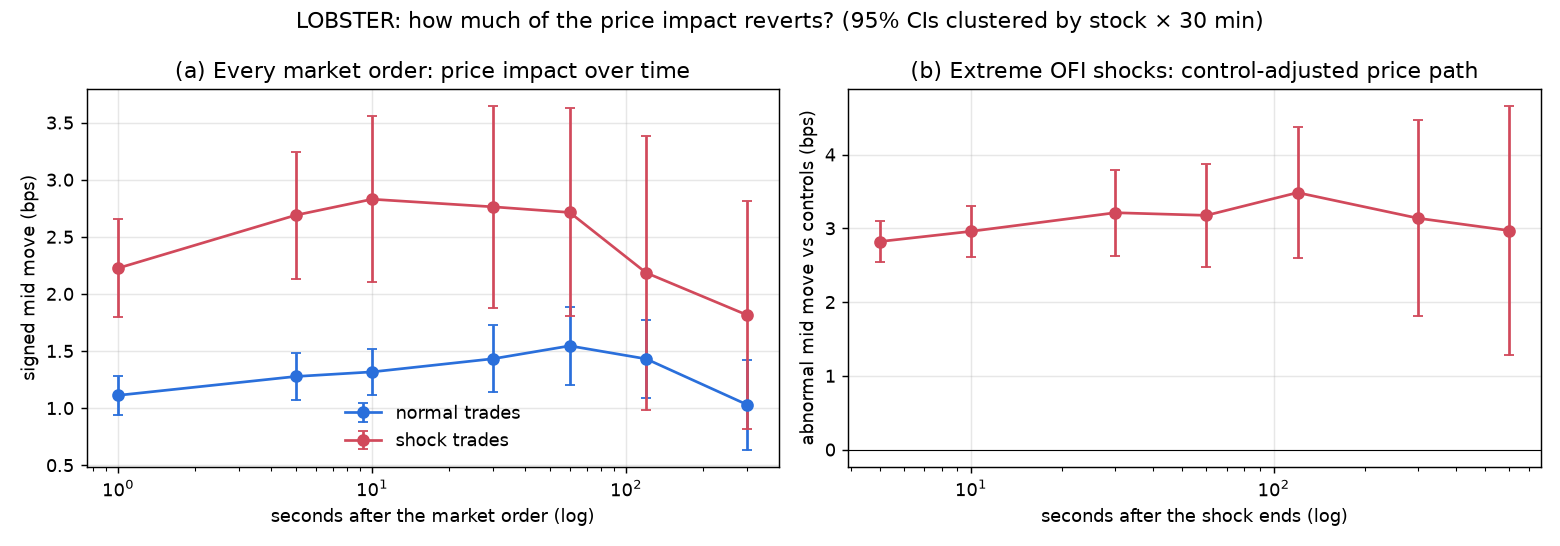

In [10]:
F("fig2_price_response_LOBSTER.png")

In [11]:
display(T("08b_price_reversal_test_trades")); display(T("08c_price_response_events_clock_time"))

,period,from_s,to_s,change_bps,se,ci_low,ci_high,t,p,impact_at_from_bps,share_reversed,n,clusters
0,normal,10,120,0.114,0.124,-0.128,0.356,0.922,0.360,1.317,-0.086,21896,60
1,normal,10,300,-0.287,0.184,-0.648,0.073,-1.563,0.123,1.317,0.218,21896,60
2,normal,60,300,-0.516,0.180,-0.869,-0.162,-2.858,0.006,1.545,0.334,21896,60
3,shock,10,120,-0.644,0.502,-1.628,0.339,-1.285,0.204,2.829,0.228,2688,60
4,shock,10,300,-1.015,0.536,-2.066,0.037,-1.892,0.063,2.829,0.359,2688,60
5,shock,60,300,-0.899,0.541,-1.958,0.160,-1.663,0.102,2.713,0.331,2688,60


,horizon_s,event_bps,control_bps,abnormal_bps,se,ci_low,ci_high,n,clusters,share_of_peak_remaining
0,0,1.900,-0.007,1.907,0.077,1.756,2.057,657,60,0.547
1,5,3.048,0.228,2.821,0.144,2.538,3.103,657,60,0.810
2,10,3.198,0.240,2.959,0.175,2.616,3.301,657,60,0.849
3,30,3.440,0.229,3.211,0.297,2.629,3.793,657,60,0.922
4,60,3.360,0.184,3.175,0.355,2.479,3.872,657,60,0.911
5,120,3.559,0.096,3.483,0.455,2.592,4.375,654,60,1.000
6,300,3.261,0.136,3.137,0.678,1.807,4.466,643,60,0.900
7,600,3.280,0.337,2.969,0.861,1.281,4.657,626,60,0.852


**Two different objects.**
* For the *average market order*, about one third of the 60-second impact reverts by 5 minutes.
* For *extreme order-flow episodes*, the control-adjusted price move peaks at about 3.5 bps after 2 minutes, and
  about 85% of that peak is still present after 10 minutes.

So shocks are followed by largely persistent price changes, and only ordinary trades show partial reversal.

## 6. Robustness grid (secondary): 24 specifications per dataset

In [12]:
rob = T("09_robustness_grid")
display(rob[rob["primary_spec"]])
summary = []
for ds, g in rob.groupby("dataset"):
    for c, tc in (("impact_bps", None), ("H1_spread", "H1_spread_t"), ("H2_flow", "H2_flow_t"),
                  ("H2_improve", "H2_improve_t"), ("drift_bps", "drift_t"), ("H3_beta", "H3_t")):
        summary.append(dict(dataset=ds, quantity=c, positive=f"{(g[c] > 0).sum()}/{len(g)}",
                            significant_5pct=None if tc is None else f"{(g[tc].abs() > 1.96).sum()}/{len(g)}"))
display(pd.DataFrame(summary))
display(T("09b_depth_imbalance_definition"))

,primary_spec,dataset,signal,W,q,K1,K2,events,impact_bps,H1_spread,H1_spread_t,H1_depth,H1_depth_t,H1_depth10,H1_depth10_t,H2_improve,H2_improve_t,H2_flow,H2_flow_t,H2_refill,H2_refill_t,drift_bps,drift_t,H3_beta,H3_t
5,True,FI-2010,ofi1n,5,0.01,10,100,1269,6.080,0.393,1.504,-0.564,-12.316,0.002,0.255,-0.071,-2.061,-0.555,-3.562,0.022,1.234,4.993,6.106,0.534,0.425
29,True,LOBSTER,ofi1n,5,0.01,10,100,657,1.895,0.754,4.747,-0.005,-0.042,-0.081,-3.036,-0.209,-3.109,-1.000,-4.425,0.047,0.779,1.261,5.696,-0.024,-0.121


,dataset,quantity,positive,significant_5pct
0,FI-2010,impact_bps,24/24,NaN
1,FI-2010,H1_spread,22/24,9/24
2,FI-2010,H2_flow,0/24,20/24
3,FI-2010,H2_improve,4/24,11/24
4,FI-2010,drift_bps,24/24,24/24
5,FI-2010,H3_beta,19/24,7/24
6,LOBSTER,impact_bps,24/24,NaN
7,LOBSTER,H1_spread,21/24,21/24
8,LOBSTER,H2_flow,0/24,20/24
9,LOBSTER,H2_improve,0/24,24/24


,dataset,signal,W,q,K1,K2,events,impact_bps,H1_spread,H1_spread_t,H1_depth,H1_depth_t,H1_depth10,H1_depth10_t,H2_improve,H2_improve_t,H2_flow,H2_flow_t,H2_refill,H2_refill_t,drift_bps,drift_t,H3_beta,H3_t
0,FI-2010,imb10,1,0.05,10,100,1796,-1.203,0.260,1.744,-0.184,-12.866,-0.102,-22.519,0.046,1.647,-0.198,-3.290,-0.052,-4.049,2.838,3.526,2.161,4.318
1,LOBSTER,imb10,1,0.05,10,100,709,-0.138,-0.041,-0.884,-0.165,-9.352,-0.129,-6.839,0.283,4.088,1.035,3.247,0.079,0.521,0.025,0.102,0.032,0.200


## 7. Exploratory: shock types

Splits defined at τ = 0 (ex ante for post-shock outcomes):
* severity tercile;
* LOBSTER: high vs low aggressive (market-order) volume during the shock window.

The volume split correlates *negatively* with OFI size, so it describes how the shock was built (trades vs
quote changes). It does not identify information vs liquidity motives.

In [13]:
display(T("10_shock_types")); display(T("10b_shock_type_diagnostics"))

,dataset,split,group,events,impact_bps,drift_abn_bps,drift_t,reversal_bps,reversal_t,H2_refill_t,H3_refill_beta,H3_refill_t,H3_flow_beta,H3_flow_t
0,FI-2010,severity,medium,423,5.180,4.755,3.105,-1.803,-1.183,0.544,1.727,1.271,0.982,0.779
1,FI-2010,severity,mild,423,5.915,5.468,3.900,-2.294,-1.785,-0.542,1.889,1.582,2.765,2.641
2,FI-2010,severity,severe,423,7.145,4.755,3.926,-1.149,-0.897,1.692,0.306,0.412,-0.230,-0.094
3,LOBSTER,severity,medium,219,2.119,1.297,3.644,-1.175,-3.321,-2.363,-0.624,-3.179,0.618,3.306
4,LOBSTER,severity,mild,219,2.089,1.325,4.287,-1.194,-4.009,-2.746,0.606,3.549,-0.211,-1.036
5,LOBSTER,severity,severe,219,1.476,1.162,2.407,-0.245,-0.622,1.163,-0.825,-2.439,-0.118,-0.320
6,LOBSTER,aggressive volume,high aggressive volume,329,1.941,2.241,5.993,-1.621,-4.740,-0.427,-0.337,-1.860,0.018,0.054
7,LOBSTER,aggressive volume,low aggressive volume,328,1.847,0.278,0.961,-0.119,-0.415,1.154,-0.653,-1.997,-0.351,-1.244


,events,"corr(|OFI shock|, price impact)",dataset,"corr(aggressive volume, |OFI shock|)","corr(aggressive volume, price impact)",mean |OFI| high-volume group,mean |OFI| low-volume group
0,1269,0.095,FI-2010,NaN,NaN,NaN,NaN
1,657,0.006,LOBSTER,-0.129,-0.022,3.879,6.367


## 8. Exploratory: dealer-theory proxies (LOBSTER)

There are no trader IDs, so the "inventory proxy" is minus aggregate signed market-order flow over a rolling
window. It is not any dealer's inventory.

| Test | Measures | Interpretation |
|---|---|---|
| D1 | future passive flow on I_w | order-flow persistence (not unwinding) |
| D2b | future return on I_w, *given future flow* | > 0 would indicate inventory-driven reversal |
| D3 | spread on \|I_w\| | Amihud–Mendelson (spread rises with imbalance) |
| D4 | spread on # orders at best / recent price improvements | order-book competition proxies, not dealer counts |
| D5 | Huang–Stoll decomposition | fails its sanity check, so descriptive only |
| D6 | passive volume and realised spreads by order age | order age ≠ trader type |

Fixed-effect choice matters (D1 placebo): block fixed effects manufacture negative coefficients on shuffled data.

In [14]:
display(T("11b_D1_fixed_effect_placebo", ["window_s", "horizon_s", "data", "fixed_effects", "beta", "t"]))
display(T("11_D1_D2_inventory_proxy", ["test", "window_s", "horizon_s", "beta", "ci_low", "ci_high", "p"]))
display(T("12_D3_spread_vs_imbalance", ["window_s", "spread_timing", "controls", "beta", "ci_low", "ci_high", "p"]))
display(T("13_D4_competition_proxies", ["test", "sample", "controls", "beta", "ci_low", "ci_high", "p"]))
display(T("13b_order_book_by_stock"))
display(T("14b_D5_sanity_check"))
display(T("14_D5_huang_stoll_exploratory"))

,window_s,horizon_s,data,fixed_effects,beta,t
0,60,10,real flow,stock x 30 min,0.069,2.386
1,60,10,real flow,stock,0.102,3.667
2,60,10,shuffled flow (placebo),stock x 30 min,-0.032,-2.209
3,60,10,shuffled flow (placebo),stock,-0.012,-0.913
4,300,60,real flow,stock x 30 min,-0.054,-1.860
5,300,60,real flow,stock,0.022,0.993
6,300,60,shuffled flow (placebo),stock x 30 min,-0.024,-1.417
7,300,60,shuffled flow (placebo),stock,0.021,1.426
8,900,10,real flow,stock x 30 min,-0.128,-4.204
9,900,10,real flow,stock,0.017,0.722


,test,window_s,horizon_s,beta,ci_low,ci_high,p
0,D1 order-flow persistence: future passive flow on I_w,60,10,0.102,0.048,0.157,0.000
1,D2a future return on I_w | past return,60,10,-0.156,-0.209,-0.104,0.000
2,"D2b future return on I_w | past return, future flow, vol, spread, ...",60,10,-0.041,-0.093,0.011,0.122
3,D1 order-flow persistence: future passive flow on I_w,60,60,0.027,-0.022,0.077,0.279
4,D2a future return on I_w | past return,60,60,-0.439,-0.765,-0.114,0.008
5,"D2b future return on I_w | past return, future flow, vol, spread, ...",60,60,-0.209,-0.539,0.121,0.214
6,D1 order-flow persistence: future passive flow on I_w,60,300,0.034,-0.010,0.078,0.131
7,D2a future return on I_w | past return,60,300,-0.846,-2.914,1.222,0.423
8,"D2b future return on I_w | past return, future flow, vol, spread, ...",60,300,0.392,-0.804,1.587,0.521
9,D1 order-flow persistence: future passive flow on I_w,300,10,0.056,0.011,0.100,0.014


,window_s,spread_timing,controls,beta,ci_low,ci_high,p
0,60,same second,no controls,0.003,-0.034,0.039,0.892
1,60,same second,+ volatility,-0.063,-0.104,-0.022,0.002
2,60,same second,"+ volatility, depth",-0.056,-0.096,-0.016,0.006
3,60,same second,"+ volatility, depth, trading volume, |past return|",0.022,-0.030,0.073,0.411
4,60,10 s later,no controls,-0.024,-0.060,0.013,0.206
5,60,10 s later,+ volatility,-0.071,-0.112,-0.029,0.001
6,60,10 s later,"+ volatility, depth",-0.064,-0.104,-0.024,0.002
7,60,10 s later,"+ volatility, depth, trading volume, |past return|",-0.016,-0.064,0.031,0.505
8,300,same second,no controls,-0.020,-0.093,0.054,0.603
9,300,same second,+ volatility,-0.048,-0.127,0.031,0.235


,test,sample,controls,beta,ci_low,ci_high,p
0,D4a spread on log(# orders at best quotes),all stocks,+ volatility,0.527,0.372,0.683,0.000
1,D4a spread on log(# orders at best quotes),all stocks,"+ volatility, depth",0.579,0.412,0.746,0.000
2,D4a spread on log(# orders at best quotes),"AAPL, all seconds","+ volatility, depth",0.151,0.087,0.215,0.000
3,D4a spread on log(# orders at best quotes),"AAPL, spread > 1 tick","+ volatility, depth",0.150,0.086,0.214,0.000
4,D4a spread on log(# orders at best quotes),"AMZN, all seconds","+ volatility, depth",0.670,0.382,0.959,0.000
5,D4a spread on log(# orders at best quotes),"AMZN, spread > 1 tick","+ volatility, depth",0.669,0.381,0.958,0.000
6,D4a spread on log(# orders at best quotes),"GOOG, all seconds","+ volatility, depth",1.050,0.752,1.349,0.000
7,D4a spread on log(# orders at best quotes),"GOOG, spread > 1 tick","+ volatility, depth",1.050,0.752,1.349,0.000
8,D4a spread on log(# orders at best quotes),"INTC, all seconds","+ volatility, depth",0.028,-0.059,0.115,0.528
9,D4a spread on log(# orders at best quotes),"MSFT, all seconds","+ volatility, depth",0.079,-0.001,0.159,0.054


,stock,orders_at_best_bid,orders_at_best_ask,spread_bps,share_one_tick,improvements_per_min,best_depth
0,AAPL,4.668,4.554,2.588,0.001,79.219,304.539
1,AMZN,5.821,6.323,5.597,0.002,32.550,356.713
2,GOOG,2.841,2.768,4.590,0.000,28.142,307.293
3,INTC,46.966,31.791,3.733,0.991,2.972,27260.005
4,MSFT,45.146,29.899,3.297,0.993,4.186,22425.682


,stock,implied_half_spread_cents,effective_half_spread_cents,quoted_half_spread_cents,implied_alpha_plus_beta
0,AAPL,2.759,4.993,5.859,0.390
1,AMZN,2.503,4.716,5.106,0.436
2,GOOG,4.663,9.248,10.438,0.407
3,INTC,0.316,0.489,0.549,0.191
4,MSFT,0.312,0.491,0.553,0.298


,variant,stock,period,n,pi_reversal,adverse_selection,se_as,inventory,se_inv,order_processing
0,A quoted S_t-1,AAPL,all,19419,0.211,0.044,0.009,0.184,0.009,0.772
1,A quoted S_t-1,AAPL,normal,18421,0.217,0.043,0.009,0.185,0.009,0.772
2,A quoted S_t-1,AAPL,shock,998,0.103,0.082,0.061,0.179,0.027,0.739
3,A quoted S_t-1,AMZN,all,6331,0.199,0.033,0.028,0.209,0.025,0.757
4,A quoted S_t-1,AMZN,normal,5957,0.207,0.028,0.027,0.218,0.023,0.754
5,A quoted S_t-1,AMZN,shock,374,0.061,0.053,0.056,0.150,0.037,0.797
6,A quoted S_t-1,GOOG,all,5831,0.204,-0.026,0.024,0.234,0.023,0.792
7,A quoted S_t-1,GOOG,normal,5531,0.209,-0.026,0.025,0.234,0.024,0.792
8,A quoted S_t-1,GOOG,shock,300,0.110,-0.016,0.068,0.226,0.035,0.790
9,A quoted S_t-1,INTC,all,6216,0.167,-0.082,0.016,0.229,0.021,0.852


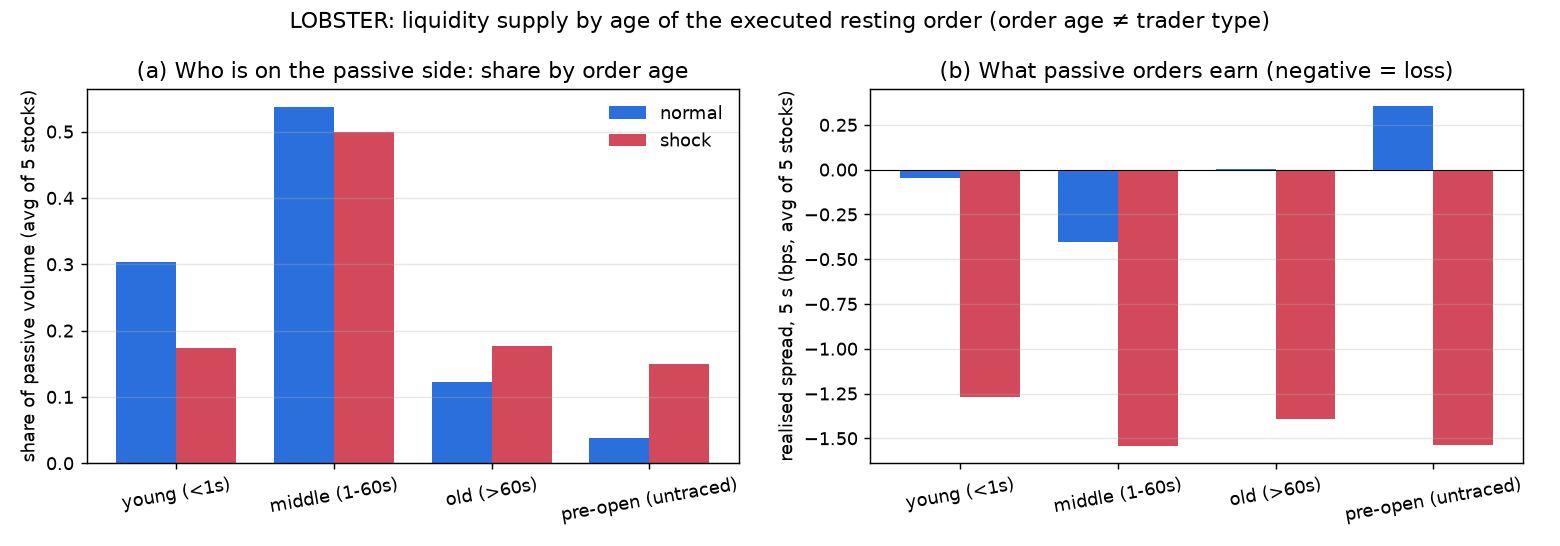

In [15]:
F("fig3_liquidity_supply_by_order_age_LOBSTER.png")

In [16]:
display(T("15_D6_order_id_matching"))
s = T("15b_D6_volume_share_by_order_age")
display(s[s["untraced_included"]])
display(T("15c_D6_performance_by_order_age")); display(T("15d_D6_regressions"))

,stock,period,executions,matched_share,matched_volume_share
0,AAPL,normal,9460.0,0.946,0.932
1,AAPL,shock,1185.0,0.696,0.628
2,AMZN,normal,4077.0,0.957,0.952
3,AMZN,shock,534.0,0.867,0.821
4,GOOG,normal,2898.0,0.971,0.965
5,GOOG,shock,408.0,0.787,0.826
6,INTC,normal,8554.0,0.980,0.982
7,INTC,shock,3862.0,0.993,0.981
8,MSFT,normal,9033.0,0.985,0.980
9,MSFT,shock,2655.0,0.995,0.994


,young_threshold_s,untraced_included,period,age_class,volume_share_equal_weight,share_AAPL,share_AMZN,share_GOOG,share_INTC,share_MSFT
0,0.1,True,normal,middle (0.1-60s),0.650,0.627,0.622,0.686,0.653,0.661
1,0.1,True,normal,old (>60s),0.122,0.050,0.061,0.065,0.224,0.209
2,0.1,True,normal,pre-open (untraced),0.038,0.068,0.048,0.035,0.018,0.020
3,0.1,True,normal,young (<0.1s),0.191,0.255,0.269,0.215,0.105,0.110
4,0.1,True,shock,middle (0.1-60s),0.572,0.445,0.422,0.565,0.664,0.764
5,0.1,True,shock,old (>60s),0.177,0.103,0.238,0.185,0.258,0.102
6,0.1,True,shock,pre-open (untraced),0.150,0.372,0.179,0.174,0.019,0.006
7,0.1,True,shock,young (<0.1s),0.101,0.079,0.161,0.076,0.058,0.128
14,1.0,True,normal,middle (1-60s),0.538,0.482,0.486,0.555,0.596,0.568
15,1.0,True,normal,old (>60s),0.122,0.050,0.061,0.065,0.224,0.209


,age_class,period,stocks,executions,realized_5s_bps,realized_60s_bps,impact_5s_bps,impact_60s_bps
0,middle (1-60s),normal,5,19431.0,-0.407,-0.733,2.126,2.453
1,middle (1-60s),shock,5,4967.0,-1.544,-2.127,3.287,3.870
2,old (>60s),normal,5,4318.0,0.002,-0.411,1.857,2.271
3,old (>60s),shock,5,1543.0,-1.395,-1.017,2.992,2.615
4,pre-open (untraced),normal,5,1077.0,0.356,-1.144,1.651,3.151
5,pre-open (untraced),shock,5,560.0,-1.539,-3.979,3.290,5.729
6,young (<1s),normal,5,9196.0,-0.049,-0.546,1.620,2.118
7,young (<1s),shock,5,1574.0,-1.270,-1.854,3.170,3.754


,test,beta,se,ci_low,ci_high,t,p,n,clusters,sig,term
0,realized_5s_bps,-1.120,0.111,-1.337,-0.903,-10.120,0.000,42666,60,***,shock
1,realized_5s_bps,0.260,0.072,0.120,0.400,3.633,0.000,42666,60,***,young
2,realized_5s_bps,0.028,0.249,-0.461,0.517,0.111,0.912,42666,60,NaN,shock_x_young
3,realized_60s_bps,-0.895,0.412,-1.703,-0.088,-2.173,0.030,42666,60,**,shock
4,realized_60s_bps,0.206,0.198,-0.181,0.594,1.043,0.297,42666,60,NaN,young
5,realized_60s_bps,-0.080,0.857,-1.760,1.601,-0.093,0.926,42666,60,NaN,shock_x_young
6,"young-order volume share, shock minus normal (paired by block)",-0.105,0.022,-0.148,-0.061,-4.744,0.000,59,59,***,share


## 9. Conclusions

See `REPORT.md` §6 for the hypothesis classification and `VALIDATION_LOG.md` for every audit performed.